# Neutral reference: old vs new

**Purpose.** A careful comparison of the neutral references used to call evolutionary activity "adaptive" in EvoCA, the ones in use and the ones replacing them (N, 2026-11-03). The new reference is tracked as [ACT-N9](ISSUES.md) (plan: [`plans/2026-11-03_full-genome-neutral-reference.md`](plans/2026-11-03_full-genome-neutral-reference.md)) and is a candidate standard.

**Sections.**
1. The two fixed-space readouts: the per-component excess (old) and the paired total-variation distance (new, N's suggestion).
2. Old vs new on 22 runs.
3. **Re-verification: the fixed-space ("tracking") shadows have no memory**, so neither readout measures selection. This was established in `Docs/shadows.md` §3.2 and §4 (2026-10-15); see the note in the summary.
4. The LUT-bucket shadow also mixes across inputs at the wrong rate.
5. What this changes in the record.
6. What a valid fixed-space reference needs.
7. (pending) The full-genome individual-based shadow (ACT-N9).

## Summary (2026-11-03)

- **New readout.** N asked why the excess is $\sum G/D_G - \sum N/D_N$ rather than a key-by-key comparison. In the fixed spaces (729 egene keys, 500 LUT buckets) the shadow gets the same total activity as the real run every tick, so the paired mean $\sum_k (G_k - N_k)$ is identically 0. The usable paired form is the total-variation distance $TV = \tfrac12 \sum_k |G_k - N_k| / \sum_k G_k \in [0, 1]$. It is in C (`evoca_eg_tv`, `evoca_dyn_tv`), with per-key getters and `run_sim` columns `eg_tv_*`, `dyn_tv_*` (commit a5ac683).
- **Computing it re-verified a known defect in the reference.** `Docs/shadows.md` §3.2 and §4 (2026-10-15) and the activity-objective guide §2.1 had already established it, as the "tracking shadow" defect, and the replacement drift shadow is built on branch `drift-shadow`. I first wrote this notebook up as a new finding without having read those; the measurements below are new, the conclusion is not. The fixed-space shadow rebuilds its composition every tick from the *real run's current composition*, $q = (1-m)\,\text{observed} + m\,\text{uniform}$, plus a small nudge, and never propagates its own state. It cannot drift away from the real run and keeps none of the real run's history, so it is not a neutral model.
  - The new readout is then an identity: $TV = \bar m \times TV(G, \text{uniform})$, to 3-4 decimals in all 22 runs (section 3).
  - The old excess is computable from the real run alone: activity per present key minus total activity over the key count, to within 0.5 out of $10^5$.
  - Both are the real run's mutation rate times its non-uniformity, or its concentration. Neither contains a selection term.
- **Consequences.** Every `eg_excess_pc`, `dyn_excess_pc` and fixed-space z-score in the record (since 2026-05-16) is a real-run diversity statistic, not an excess over neutral. That includes the egene-tax contrast and Pareto pair B (Activity-metrics section 4a′), the ACT-D1 recommendation (c), and the causal-control "frozen reads 0" validation, which holds trivially because $m = 0$. Details in section 5.
- **The LUT-bucket shadow has a second defect.** Its mixing weight is the number of flips per birth, about 2.5, so $m \approx 0.92$ per tick is applied to the whole population. The real rate is about $10^{-4}$: the birth fraction times the per-bit rate. The mass is spread across LUT inputs, which mutation cannot change. 99% of `dyn_tv` is that input smear.
- **Repair.** Already designed and built: the drift shadow (`Docs/shadows.md` §5, branch `drift-shadow`) carries full genomes with memory and projects them exactly as needed here. Its validation (2026-10-18) found that its panmictic null fails EvoCA's neutral-marker test, so the open decision is a pedigree-conditioned shadow (`plans/2026-10-18_drift-shadow-findings.md`, D1). Sections 6 and 7; `Docs/shadows.md` §14.


In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 200)
HERE = os.path.abspath('')
ROOT = os.path.normpath(os.path.join(HERE, '..', '..'))
sys.path.insert(0, os.path.join(ROOT, 'python'))
RUNS = os.path.join(HERE, 'Scans', '2026-11-03_tv_old_vs_new')
sys.path.insert(0, RUNS)
import runs                      # the driver: configs, dyn_tv_split
d = pd.read_csv(os.path.join(RUNS, 'runs.csv'))
Z = np.load(os.path.join(RUNS, 'runs.npz'))
print(len(d), 'runs;', runs.N, 'x', runs.N, 'lattice,', runs.STEPS, 'steps')

22 runs; 128 x 128 lattice, 6000 steps


## 1. The two readouts

Both live in the **fixed spaces**: 729 ternary egene keys (each active slot is one count) and 500 LUT buckets (LUT input × output bit, one count per alive cell per tick). Each space has a closed-form drift shadow inside `evoca_step` (`fs_space_step`, `C/evoca.c`; added 2026-05-16, commit b975beb). With $G_k, N_k$ the cumulative real and shadow activities of key $k$:

| | definition | denominator |
|---|---|---|
| old: `eg_excess_pc`, `dyn_excess_pc` | $\sum_{k\,\text{present}} G_k / D_G - \sum_k N_k / D_N$ | number of keys (present now; touched by the shadow) |
| paired mean (N's form) | $\sum_k (G_k - N_k) / D$ | identically 0: the shadow receives the same total mass $T$ as the real run each tick |
| new: `eg_tv`, `dyn_tv` | $\tfrac12 \sum_k \lvert G_k - N_k\rvert / \sum_k G_k$ | total activity, so it lies in $[0, 1]$ |

TV is the fraction of all activity that the real run placed differently from the shadow, key by key. Population cancels and no diversity count divides it, so it has none of the $D_G = 1$ blow-ups (ACT-Q3).

The arms: the decomposition configs (cfg 57 untaxed and cfg 275 taxed, the median-`eg`-slope configs of each egene-tax stratum of the pure-evo joint rescan), and the causal-control arms of Activity-metrics section 3 plus a fully frozen arm. N = 128, 6000 steps, 3-4 seeds.

In [2]:
cols = ['eg_excess_pc_final', 'eg_excess_pc_slope', 'eg_tv_final', 'eg_D_final',
        'dyn_excess_pc_final', 'dyn_excess_pc_slope', 'dyn_tv_final', 'dyn_D_final', 'alive']
g = d.groupby(['group', 'name'], sort=False)
tab = g[cols].mean()
cv = (g[['eg_excess_pc_slope', 'eg_tv_final']].std() / g[['eg_excess_pc_slope', 'eg_tv_final']].mean()).add_suffix('_cv')
display(tab.round(3))
display(cv.round(3))

eg_excess_pc_final  eg_excess_pc_slope  eg_tv_final  eg_D_final  dyn_excess_pc_final  dyn_excess_pc_slope  dyn_tv_final  dyn_D_final  alive
group  name                                                                                                                                                   
causal EGENE_only          146950.060              23.753        0.022     124.750                0.250                0.000         0.000        1.000  0.263
       FROZEN                   0.000               0.000        0.000       1.000                0.250                0.000         0.000        1.000  0.157
       JOINT               161459.119              26.072        0.023     111.500            61631.703               10.847         0.685      210.250  0.271
       LUT_only                 0.000               0.000        0.000       1.000            44714.125                7.730         0.672      195.000  0.159
decomp cfg275              128279.526              23.671        0.075     225.667            67449.924               11.119         0.714      231.333  0.347
       cfg57                 5305.596               0.891        0.026     691.000            46699.037                7.865         0.695      243.000  0.235

eg_excess_pc_slope_cv  eg_tv_final_cv
group  name                                             
causal EGENE_only                  0.019           0.011
       FROZEN                        NaN             NaN
       JOINT                       0.085           0.013
       LUT_only                      NaN             NaN
decomp cfg275                      0.094           0.008
       cfg57                       0.109           0.018

## 2. Old vs new, read at face value

Read as if the shadow were a neutral model:

- **The frozen-subsystem checks pass for both forms.** The egene channel reads exactly 0 in LUT_only and FROZEN, the LUT channel exactly 0 in EGENE_only and FROZEN.
- **The egene-tax contrast shrinks.** Old: untaxed cfg 57 about 5e3, taxed cfg 275 about 1.3e5, a 25-fold gap. New: 0.026 vs 0.075, a 3-fold gap. Untaxed cfg 57's egene TV is also *above* the taxed JOINT arm's (0.023). So the "void" untaxed egene channel of section 4a′ was the diversity denominator (691 vs 240 keys present).
- **TV is steadier across seeds.** CV is 0.01-0.03 versus 0.02-0.11 for the old slope. The test fixture is starker: old egene excess 270 to 11,900 across three seeds, TV 0.030-0.032.
- **The LUT channel reads about 0.7 in every mutating run.**

That last value is what prompted the check in section 3.

## 3. Re-verification: the fixed-space shadows have no memory

The shadow update, condensed from `fs_space_step` (`C/evoca.c`):

```c
double m = 1.0 - exp(-flux_rate);                 // flux_rate = flips / (births x bits per component)
for (k...) {
    double obs_f = obs_pop[k] / T;                // the REAL run's composition this tick
    double qk = (1.0 - m) * obs_f + m * u_all;    // blend with uniform over all K keys
    qk += (m / Np) * (target - qk);               // small nudge toward uniform-over-occupied
    q[k] = qk;                                    // q is rebuilt; the previous q is never used
}
nact[k] += T * q[k];                              // shadow activity
```

The comment above it states the premise: "Under the neutral NULL there is no selection, so the shadow's expected composition equals the *realised* composition." That is circular. The realized composition is the product of selection, so a shadow anchored to it every tick inherits whatever selection did, and it keeps none of the real run's history. A neutral reference must evolve its *own* composition from its *own* past under the real demography; that is what Channon's shadow population does.

**Consequence: the readouts are identities.** Per tick, $N_k$ grows by $T[(1-m)\,o_k + m/K]$ and $G_k$ by $T\,o_k$, so $G_k - N_k$ accumulates $T\,m\,(o_k - 1/K)$. With $m$ roughly constant:

$$TV \approx \bar m \cdot TV(G/\textstyle\sum G,\ \text{uniform}).$$

The old excess reduces further. Once $m > 0$ the shadow touches every key ($D_N = K$) and $\sum N = \sum G$, so

$$\text{excess} = \frac{\sum_{k\,\text{present}} G_k}{D_G} - \frac{\sum_k G_k}{K}.$$

That is computed from the real run alone; the shadow enters only through $K$.

In [3]:
d['eg_tv_pred'] = d.eg_m_mean * d.eg_tv_vs_uniform
d['dyn_tv_pred'] = d.dyn_m_mean * d.dyn_tv_vs_uniform
show = ['name', 'seed', 'eg_m_mean', 'eg_tv_vs_uniform', 'eg_tv_pred', 'eg_tv_final',
        'dyn_m_mean', 'dyn_tv_pred', 'dyn_tv_final', 'eg_excess_pc_final', 'eg_excess_real_only',
        'dyn_excess_pc_final', 'dyn_excess_real_only']
display(d[show].round(4))
for ch in ('eg', 'dyn'):
    m = d[f'{ch}_m_mean'] > 0          # frozen arms: m = 0 and both sides are exactly 0
    rel = (d.loc[m, f'{ch}_tv_pred'] / d.loc[m, f'{ch}_tv_final'] - 1).abs().max()
    ex = (d[f'{ch}_excess_pc_final'] - d[f'{ch}_excess_real_only']).abs().max()
    print(f'{ch}: TV prediction within {100*rel:.2f}% (max over runs);  old excess minus real-only formula: max |diff| {ex:.2f}')

,name,seed,eg_m_mean,eg_tv_vs_uniform,eg_tv_pred,eg_tv_final,dyn_m_mean,dyn_tv_pred,dyn_tv_final,eg_excess_pc_final,eg_excess_real_only,dyn_excess_pc_final,dyn_excess_real_only
0,EGENE_only,0,0.0270,0.8122,0.0219,0.0219,0.0000,0.0000,0.0000,141568.7340,141568.2443,0.0000,0.0000
1,EGENE_only,1,0.0269,0.8072,0.0217,0.0218,0.0000,0.0000,0.0000,143994.4547,143993.9348,0.0000,0.0000
2,EGENE_only,2,0.0271,0.7974,0.0216,0.0216,0.0000,0.0000,0.0000,148678.9318,148678.4325,0.0000,0.0000
3,EGENE_only,3,0.0270,0.7912,0.0214,0.0214,0.0000,0.0000,0.0000,153558.1194,153557.6118,1.0000,0.0000
4,FROZEN,0,0.0000,0.9986,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
5,FROZEN,1,0.0000,0.9986,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
6,FROZEN,2,0.0000,0.9986,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
7,FROZEN,3,0.0000,0.9986,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
8,JOINT,0,0.0269,0.8402,0.0226,0.0227,0.9139,0.6871,0.6881,141753.5916,141753.0662,55862.5916,55862.1196
9,JOINT,1,0.0269,0.8525,0.0229,0.0230,0.9139,0.6867,0.6874,191678.1171,191677.5972,68839.6500,68839.1480


eg: TV prediction within 0.36% (max over runs);  old excess minus real-only formula: max |diff| 0.53
dyn: TV prediction within 0.31% (max over runs);  old excess minus real-only formula: max |diff| 1.00


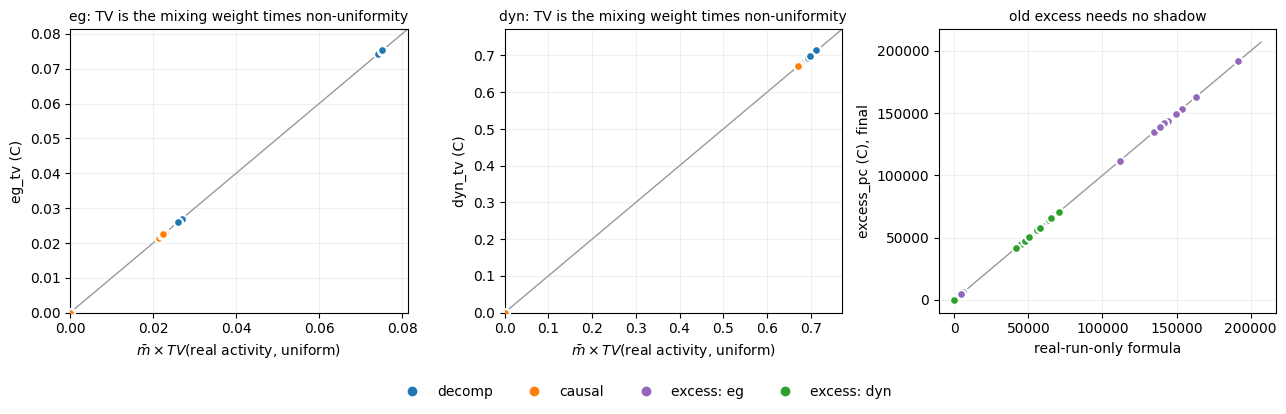

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
C = {'decomp': '#1f77b4', 'causal': '#ff7f0e'}
for ax, ch in zip(axs[:2], ('eg', 'dyn')):
    for grp, sub in d.groupby('group'):
        ax.scatter(sub[f'{ch}_tv_pred'], sub[f'{ch}_tv_final'], s=40, color=C[grp], label=grp,
                   edgecolor='white', linewidth=1.5, zorder=3)
    hi = max(d[f'{ch}_tv_final'].max(), d[f'{ch}_tv_pred'].max()) * 1.08
    ax.plot([0, hi], [0, hi], color='0.6', lw=1, zorder=1)
    ax.set_xlim(0, hi); ax.set_ylim(0, hi)
    ax.set_xlabel(r'$\bar m \times TV$(real activity, uniform)')
    ax.set_ylabel(f'{ch}_tv (C)')
    ax.set_title(f'{ch}: TV is the mixing weight times non-uniformity', fontsize=10)
    ax.grid(alpha=0.2)
ax = axs[2]
for ch, col in (('eg', '#9467bd'), ('dyn', '#2ca02c')):
    ax.scatter(d[f'{ch}_excess_real_only'], d[f'{ch}_excess_pc_final'], s=40, color=col, label=ch,
               edgecolor='white', linewidth=1.5, zorder=3)
hi = d[['eg_excess_pc_final', 'dyn_excess_pc_final']].max().max() * 1.08
ax.plot([0, hi], [0, hi], color='0.6', lw=1, zorder=1)
ax.set_xlabel('real-run-only formula'); ax.set_ylabel('excess_pc (C), final')
ax.set_title('old excess needs no shadow', fontsize=10); ax.grid(alpha=0.2)
handles = [plt.Line2D([], [], marker='o', ls='', color=C[k], label=k) for k in C] + \
          [plt.Line2D([], [], marker='o', ls='', color=c, label=f'excess: {k}') for k, c in (('eg', '#9467bd'), ('dyn', '#2ca02c'))]
fig.legend(handles=handles, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.04), frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**Reading.** Every point lies on the identity line in all three panels; the frozen arms sit at the origin. So:

- the "frozen reads 0" causal check is satisfied because $m = 0$, not because the reference detects the absence of selection;
- an evolving subsystem reads above 0 because $m > 0$ and its composition is not uniform. A non-uniform composition is present under pure drift as well (founder effects; GoL-seeded LUTs; one initial egene). Here **no test separates selection from drift**;
- differences between configs in either readout are differences in mutation rate, diversity and concentration. These are worth having as descriptive statistics, but they are not excess activity.

The fixed-space z-scores (`get_eg_zscores`, `get_dyn_zscores`, G2) share the numerator $G_k - N_k = \sum_t T m (o_k - 1/K)$ and therefore the same defect.

## 4. The LUT-bucket shadow: wrong rate, wrong kernel

Two further problems specific to the 500-bucket space:

1. **The rate.** `DYN_BITS_PER_COMPONENT = 1`, so the rate is LUT flips per birth, about $250 \mu_{lut} = 2.5$ at `mu_lut` 0.01, which gives $m = 1 - e^{-2.5} \approx 0.92$, applied to *all* mass every tick. The mass that mutation actually moves per tick is about (birth fraction) × (per-bit rate) $\approx 0.011 \times 0.01 \approx 10^{-4}$. The shadow is therefore about 92% uniform every tick.
2. **The kernel.** A bucket is (input, output). A LUT mutation flips the output for one input. It cannot change how often an input occurs, because that is set by the lattice dynamics. The shadow spreads mass uniformly over all 500 buckets, across inputs.

`runs.dyn_tv_split` separates the input-marginal part from the within-input (output-choice) part, weighted by the real run's input use:

In [5]:
display(d.groupby(['group', 'name'], sort=False)[['dyn_m_mean', 'dyn_tv_final', 'dyn_tv_input_final',
                                                 'dyn_tv_within_final']].mean().round(3))

dyn_m_mean  dyn_tv_final  dyn_tv_input_final  dyn_tv_within_final
group  name                                                                         
causal EGENE_only       0.000         0.000               0.000                0.000
       FROZEN           0.000         0.000               0.000                0.000
       JOINT            0.914         0.685               0.685                0.063
       LUT_only         0.915         0.672               0.672                0.053
decomp cfg275           0.997         0.714               0.714                0.082
       cfg57            1.000         0.695               0.695                0.086

About 99% of `dyn_tv` is the input-marginal smear. The within-input part (0.05-0.09) is the only part that could carry a selection signal. Even it is measured against "92% of each input's mass split 50/50", not against a neutral lineage history. The old `dyn_excess_pc` inherits the same smear through $D_N = 500$.

## 5. What this changes in the record

| recorded claim | status |
|---|---|
| `eg`/`dyn` excess as "excess over neutral drift" (since 2026-05-16, all workstreams) | **withdrawn as stated**; re-read as real-run concentration statistics |
| Causal controls: frozen subsystem reads 0, evolving subsystem reads > 0 (Activity-metrics section 3) | holds, but trivially ($m = 0$ vs $m > 0$); not a validation of the reference |
| Egene-tax strata differ in kind; untaxed `eg` "mostly flat" (4a′) | mostly a diversity effect (25-fold old vs 3-fold TV); neither number is a selection measure |
| Pareto pair B on (`eg`, `dyn`) excess (ACT-D2, ACT-N8 plan) | the objective pair is invalid until the reference is fixed |
| ACT-D1 recommendation (c): two-channel vector on fixed-space shadows | needs revising; the channel structure is right, the reference is not |
| ACT-Q3 (`eg` excess explodes when one key is present) and the `dyn` frozen-rich-substrate artifact (ACT-Q10) | explained: the excess is $\sum_{\text{present}} G / D_G - \sum G / K$, large whenever $D_G \ll K$ |
| Channon LUT-hash shadow (`excess_pc_*`, `A_new`) | not affected by this defect. It is a real individual-based shadow; its own defects are the key mismatch and the seeding split (ACT-N9) |
| CHEM-N7 activity readouts | not affected (LUT-hash activity and flux, no fixed-space excess) |

Documents that quote fixed-space excess numbers: Activity-metrics (plans, scans, notebook), Lineage-co-evolution (#3c and plans), Resource-driving (food_cap impact), Reaction-diffusion, Docs and devlog. They are not edited here; the issue is filed as ACT-Q11 and linked from them as they are next touched.

## 6. What a valid fixed-space reference needs

The two readouts are fine as statistics. TV in particular is bounded, steady across seeds, and blind to diversity. What needs replacing is the reference distribution.

| option | what it is | cost | drawback |
|---|---|---|---|
| A. memory in the closed form | propagate $q_{t+1}$ from $q_t$ with the real births and a correct kernel (egene: 12-bit flips mapped to ternary keys; LUT: within-input output flips at the per-bit rate) | about half a day in C | still mean-field. It has no drift variance, and drift inflates TV even under neutrality, so it needs a null distribution as well |
| **B. projections of the ACT-N9 shadow** (recommended) | the full-genome individual shadow carries egenes and LUTs through the real births and deaths. Egene keys: histogram of the shadow individuals' slots. LUT buckets: real input use × the shadow population's output fraction per input | part of ACT-N9 (about 2-3 days already planned) | none beyond ACT-N9 itself; drift is included because the shadow is a finite population |
| C. replicate shadows for the null | several shadow populations with independent RNG streams; the TV between two shadows gives the neutral spread of TV | cheap once B exists | memory and time scale with the replicate count |

**Status (later on 2026-11-03).** B and C are what the drift shadow already is (`Docs/shadows.md` §5, branch `drift-shadow`: replicate full-genome populations, design C for dyn, TV among its statistics). Its 2026-10-18 validation found the panmictic null fails EvoCA's marker test (marker $z$ from $-3.9$ to $-18$). So the recommendation is the 2026-10-18 one: a pedigree-conditioned shadow (D1 of `plans/2026-10-18_drift-shadow-findings.md`). Until then, report the fixed-space numbers only as concentration statistics, under names that say so.

## 7. The replacement reference (pending)

To be added once N decides the 2026-10-18 D1: the drift-shadow (or pedigree-shadow) readouts against the tracking ones on the same arms, the Channon-specific repairs of ACT-N9 (seeding split, full-genome keys, clonal flux) if kept, and torque validation runs.